In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))
!nvidia-smi

True Tesla T4
Fri Nov 13 21:56:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------------------

In [15]:
DATA = "/kaggle/input/dnnfiles/"      # read-only
OUT  = "/kaggle/working/"                   # where outputs and checkpoints go

In [16]:
!ls /kaggle/input/dnnfiles/

ls: cannot access '/kaggle/input/dnnfiles/': No such file or directory


In [17]:
!ls /kaggle/input
!find /kaggle/input -maxdepth 4 | head -50

datasets
/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/hasikabasireddy
/kaggle/input/datasets/hasikabasireddy/dnnfiles
/kaggle/input/datasets/hasikabasireddy/dnnfiles/build_grids.py
/kaggle/input/datasets/hasikabasireddy/dnnfiles/export_hl_mc.py
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_grids_ee.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_grids_mumu.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_grids_qcd.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_grids_tau.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_ee.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_mumu.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_qcd.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_tau.npz
/kaggle/input/datasets/hasikabasireddy/dnnfiles/plot_roc_mc.py
/kaggle/input/datasets/hasikabasireddy/dnnfiles/smoke_test_mc.py
/kaggle/input/datasets/hasikabasireddy/dnnfiles/train_deeptau_mc.py


In [19]:
DATA = "/kaggle/input/datasets/hasikabasireddy/dnnfiles/"

In [20]:
!ls /kaggle/input/datasets/hasikabasireddy/dnnfiles/

build_grids.py	   mc_grids_qcd.npz  mc_hl_qcd.npz     train_deeptau_mc.py
export_hl_mc.py    mc_grids_tau.npz  mc_hl_tau.npz
mc_grids_ee.npz    mc_hl_ee.npz      plot_roc_mc.py
mc_grids_mumu.npz  mc_hl_mumu.npz    smoke_test_mc.py


In [24]:
DATA = "/kaggle/input/datasets/hasikabasireddy/dnnfiles/"

In [25]:
DATA = "/kaggle/input/datasets/hasikabasireddy/dnnfiles/"      # read-only
OUT  = "/kaggle/working/"                   # where outputs and checkpoints go

In [26]:
%cd /kaggle/working
!cp /kaggle/input/datasets/hasikabasireddy/dnnfiles/*.py .
!ls

/kaggle/working
build_grids.py	 plot_roc_mc.py    train_deeptau_mc.py
export_hl_mc.py  smoke_test_mc.py


In [27]:
!python train_deeptau_mc.py --help
!python smoke_test_mc.py --help
!grep -n "np.load\|\.npz\|torch.save\|/home\|~/" train_deeptau_mc.py smoke_test_mc.py

usage: train_deeptau_mc.py [-h] [--mode {hl,full}] --hl-qcd HL_QCD
                           [--grids-qcd GRIDS_QCD] --hl-tau HL_TAU
                           [--grids-tau GRIDS_TAU] --hl-mumu HL_MUMU
                           [--grids-mumu GRIDS_MUMU] --hl-ee HL_EE
                           [--grids-ee GRIDS_EE] [--epochs EPOCHS]
                           [--batch BATCH] [--lr LR] [--workers WORKERS]
                           [--scale SCALE]
                           [--mask-grid-features MASK_GRID_FEATURES]
                           [--max-events MAX_EVENTS] [--seed SEED] [--out OUT]
                           [--resume] [--dry-run]

train_deeptau_mc.py -- MULTICLASS DeepTau-style classifier (CMS DeepTau paper, arXiv:2201.08458, Fig. 3).
Four classes, one per sample (label in brackets):
    jet (0) = QCD sample     tau (1) = tau sample     muon (2) = mumu sample     electron (3) = ee sample
The tau candidate is the one the analyzer selected (tauHLIndex); every sample uses its

In [28]:
%cd /kaggle/working
D = "/kaggle/input/datasets/hasikabasireddy/dnnfiles"
!cp {D}/*.py .
!ls

/kaggle/working
build_grids.py	 plot_roc_mc.py  smoke_test_mc.py
export_hl_mc.py  __pycache__	 train_deeptau_mc.py


In [29]:
!python train_deeptau_mc.py --mode full \
  --hl-qcd {D}/mc_hl_qcd.npz   --grids-qcd {D}/mc_grids_qcd.npz \
  --hl-tau {D}/mc_hl_tau.npz   --grids-tau {D}/mc_grids_tau.npz \
  --hl-mumu {D}/mc_hl_mumu.npz --grids-mumu {D}/mc_grids_mumu.npz \
  --hl-ee {D}/mc_hl_ee.npz     --grids-ee {D}/mc_grids_ee.npz \
  --dry-run

loading ...
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_qcd.npz  284871 selected rows of 416243   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_tau.npz   43607 selected rows of 43607   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_mumu.npz  139614 selected rows of 140591   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_ee.npz   74927 selected rows of 85902   (41 variables)
tau-candidate kinematics per class (pT quartiles in GeV, mean |eta|):
  jet       n= 284871   pT   35.8   64.2  124.7   mean|eta| 0.97
  tau       n=  43607   pT   33.7   51.4   74.5   mean|eta| 1.03
  muon      n= 139614   pT   61.0   68.9   79.9   mean|eta| 1.15
  electron  n=  74927   pT   60.5   68.6   79.9   mean|eta| 1.11
grid features that are non-zero for at least one particle (1 = filled, 0 = all zero):
                                 qcd     tau    mumu      ee
  pvAssociationQuality  [masked]       1       1       1     

In [30]:
!python train_deeptau_mc.py --mode full \
  --hl-qcd {D}/mc_hl_qcd.npz   --grids-qcd {D}/mc_grids_qcd.npz \
  --hl-tau {D}/mc_hl_tau.npz   --grids-tau {D}/mc_grids_tau.npz \
  --hl-mumu {D}/mc_hl_mumu.npz --grids-mumu {D}/mc_grids_mumu.npz \
  --hl-ee {D}/mc_hl_ee.npz     --grids-ee {D}/mc_grids_ee.npz \
  --max-events 3000 --scale 0.25 --epochs 1 --workers 2 --out /kaggle/working/test_run

loading ...
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_qcd.npz    3000 selected rows of 416243   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_tau.npz    3000 selected rows of 43607   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_mumu.npz    3000 selected rows of 140591   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_ee.npz    3000 selected rows of 85902   (41 variables)
tau-candidate kinematics per class (pT quartiles in GeV, mean |eta|):
  jet       n=   3000   pT   34.5   62.6  124.6   mean|eta| 0.98
  tau       n=   3000   pT   33.7   51.6   74.8   mean|eta| 1.04
  muon      n=   3000   pT   60.9   68.9   79.8   mean|eta| 1.15
  electron  n=   3000   pT   60.7   69.0   80.7   mean|eta| 1.11
grid features that are non-zero for at least one particle (1 = filled, 0 = all zero):
                                 qcd     tau    mumu      ee
  pvAssociationQuality  [masked]       1       1       1     

In [31]:
!python train_deeptau_mc.py --mode full \
  --hl-qcd {D}/mc_hl_qcd.npz   --grids-qcd {D}/mc_grids_qcd.npz \
  --hl-tau {D}/mc_hl_tau.npz   --grids-tau {D}/mc_grids_tau.npz \
  --hl-mumu {D}/mc_hl_mumu.npz --grids-mumu {D}/mc_grids_mumu.npz \
  --hl-ee {D}/mc_hl_ee.npz     --grids-ee {D}/mc_grids_ee.npz \
  --epochs 20 --workers 4 --resume --out /kaggle/working/mc_deeptau_full

loading ...
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_qcd.npz  284871 selected rows of 416243   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_tau.npz   43607 selected rows of 43607   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_mumu.npz  139614 selected rows of 140591   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_ee.npz   74927 selected rows of 85902   (41 variables)
tau-candidate kinematics per class (pT quartiles in GeV, mean |eta|):
  jet       n= 284871   pT   35.8   64.2  124.7   mean|eta| 0.97
  tau       n=  43607   pT   33.7   51.4   74.5   mean|eta| 1.03
  muon      n= 139614   pT   61.0   68.9   79.9   mean|eta| 1.15
  electron  n=  74927   pT   60.5   68.6   79.9   mean|eta| 1.11
grid features that are non-zero for at least one particle (1 = filled, 0 = all zero):
                                 qcd     tau    mumu      ee
  pvAssociationQuality  [masked]       1       1       1     

In [32]:
!python -u train_deeptau_mc.py --mode full \
  --hl-qcd {D}/mc_hl_qcd.npz   --grids-qcd {D}/mc_grids_qcd.npz \
  --hl-tau {D}/mc_hl_tau.npz   --grids-tau {D}/mc_grids_tau.npz \
  --hl-mumu {D}/mc_hl_mumu.npz --grids-mumu {D}/mc_grids_mumu.npz \
  --hl-ee {D}/mc_hl_ee.npz     --grids-ee {D}/mc_grids_ee.npz \
  --epochs 10 --workers 4 --resume --out /kaggle/working/mc_deeptau_full 2>&1 | tee /kaggle/working/train_log.txt

loading ...
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_qcd.npz  284871 selected rows of 416243   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_tau.npz   43607 selected rows of 43607   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_mumu.npz  139614 selected rows of 140591   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_ee.npz   74927 selected rows of 85902   (41 variables)
tau-candidate kinematics per class (pT quartiles in GeV, mean |eta|):
  jet       n= 284871   pT   35.8   64.2  124.7   mean|eta| 0.97
  tau       n=  43607   pT   33.7   51.4   74.5   mean|eta| 1.03
  muon      n= 139614   pT   61.0   68.9   79.9   mean|eta| 1.15
  electron  n=  74927   pT   60.5   68.6   79.9   mean|eta| 1.11
grid features that are non-zero for at least one particle (1 = filled, 0 = all zero):
                                 qcd     tau    mumu      ee
  pvAssociationQuality  [masked]       1       1       1     

In [1]:
evalscript

NameError: name 'evalscript' is not defined

In [2]:
!find /kaggle/input -name eval_wp.py

/kaggle/input/datasets/hasikabasireddy/evalscript/eval_wp.py


In [3]:
!python /kaggle/input/datasets/hasikabasireddy/evalscript/eval_wp.py/kaggle/working/mc_deeptau_full_test_scores.npz --out /kaggle/working/roc_paper_style.png

python3: can't open file '/kaggle/input/datasets/hasikabasireddy/evalscript/eval_wp.py/kaggle/working/mc_deeptau_full_test_scores.npz': [Errno 20] Not a directory


In [4]:
!python /kaggle/input/datasets/hasikabasireddy/evalscript/eval_wp.py /kaggle/working/mc_deeptau_full_test_scores.npz --out /kaggle/working/roc_paper_style.png

Traceback (most recent call last):
  File "/kaggle/input/datasets/hasikabasireddy/evalscript/eval_wp.py", line 20, in <module>
    z = np.load(a.scores, allow_pickle=True)
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 459, in load
    fid = stack.enter_context(open(os.fspath(file), "rb"))
                              ~~~~^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/mc_deeptau_full_test_scores.npz'


In [ ]:
!python -u train_deeptau_mc.py --mode full \
  --hl-qcd {D}/mc_hl_qcd.npz   --grids-qcd {D}/mc_grids_qcd.npz \
  --hl-tau {D}/mc_hl_tau.npz   --grids-tau {D}/mc_grids_tau.npz \
  --hl-mumu {D}/mc_hl_mumu.npz --grids-mumu {D}/mc_grids_mumu.npz \
  --hl-ee {D}/mc_hl_ee.npz     --grids-ee {D}/mc_grids_ee.npz \
  --epochs 10 --workers 4 --resume --out /kaggle/working/mc_deeptau_full 2>&1 | tee /kaggle/working/train_log.txt

In [10]:
!find /kaggle/input -name leak_check.py

In [11]:
%cd /kaggle/working
D = "/kaggle/input/datasets/hasikabasireddy/dnnfiles"
!cp {D}/*.py .
!ls

/kaggle/working
build_grids.py	 plot_roc_mc.py    train_deeptau_mc.py
export_hl_mc.py  smoke_test_mc.py


In [12]:
!nvidia-smi

Sat Nov 14 09:04:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [13]:
!python -u train_deeptau_mc.py --mode full \
  --hl-qcd {D}/mc_hl_qcd.npz   --grids-qcd {D}/mc_grids_qcd.npz \
  --hl-tau {D}/mc_hl_tau.npz   --grids-tau {D}/mc_grids_tau.npz \
  --hl-mumu {D}/mc_hl_mumu.npz --grids-mumu {D}/mc_grids_mumu.npz \
  --hl-ee {D}/mc_hl_ee.npz     --grids-ee {D}/mc_grids_ee.npz \
  --epochs 10 --workers 4 --out /kaggle/working/mc_deeptau_full 2>&1 | tee /kaggle/working/train_log.txt

loading ...
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_qcd.npz  284871 selected rows of 416243   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_tau.npz   43607 selected rows of 43607   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_mumu.npz  139614 selected rows of 140591   (41 variables)
  /kaggle/input/datasets/hasikabasireddy/dnnfiles/mc_hl_ee.npz   74927 selected rows of 85902   (41 variables)
tau-candidate kinematics per class (pT quartiles in GeV, mean |eta|):
  jet       n= 284871   pT   35.8   64.2  124.7   mean|eta| 0.97
  tau       n=  43607   pT   33.7   51.4   74.5   mean|eta| 1.03
  muon      n= 139614   pT   61.0   68.9   79.9   mean|eta| 1.15
  electron  n=  74927   pT   60.5   68.6   79.9   mean|eta| 1.11
grid features that are non-zero for at least one particle (1 = filled, 0 = all zero):
                                 qcd     tau    mumu      ee
  pvAssociationQuality  [masked]       1       1       1     

In [14]:
"""Working-point table in the style of DeepTau paper Table 3 (arXiv:2201.08458).
usage: python wp_table.py mc_deeptau_full_test_scores.npz [out_prefix]
For each discriminator D_a = y_tau/(y_tau+y_a): cut on D_a that gives the paper's target tau efficiency,
the efficiency actually achieved, and the resulting a->tau misid probability (zero counts -> 95% CL upper limit 3/N)."""
import sys, csv, numpy as np
z=np.load(sys.argv[1],allow_pickle=True); pref=sys.argv[2] if len(sys.argv)>2 else 'wp_table'
p=z['prob'].astype(np.float64); y=z['label']; names=[str(n) for n in z['class_names']]; t=names.index('tau')
WP=['VVTight','VTight','Tight','Medium','Loose','VLoose','VVLoose','VVVLoose']
TARGET={'electron':[.60,.70,.80,.90,.95,.98,.99,.995],
        'muon':[None,None,.995,.998,.999,.9995,None,None],
        'jet':[.40,.50,.60,.70,.80,.90,.95,.98]}
rows=[]
for a in ['electron','muon','jet']:
    ai=names.index(a); D=p[:,t]/(p[:,t]+p[:,ai]+1e-30)
    dt=D[y==t]; db=D[y==ai]; nb=len(db)
    for wp,e in zip(WP,TARGET[a]):
        if e is None: rows.append([a,wp,'','','','']); continue
        thr=np.quantile(dt,1-e,method='lower'); eff=(dt>=thr).mean(); k=(db>=thr).sum()
        rows.append([a,wp,e,round(float(thr),5),round(float(eff),4),k/nb if k>0 else None, k, nb])
hdr=['discriminator','working_point','target_tau_eff','cut_on_D','achieved_tau_eff','misid','n_bkg_passing','n_bkg']
with open(pref+'.csv','w',newline='') as f:
    w=csv.writer(f); w.writerow(hdr)
    for r in rows: w.writerow(r)
for r in rows: print(r)

FileNotFoundError: [Errno 2] No such file or directory: '-f'

In [17]:
import numpy as np, pandas as pd

SCORES = "/kaggle/working/mc_deeptau_full_test_scores.npz"   # <- your file
OUT    = "/kaggle/working/wp_table.csv"

z = np.load(SCORES, allow_pickle=True)
p = z["prob"].astype(np.float64); y = z["label"]
names = [str(n) for n in z["class_names"]]; t = names.index("tau")

WP = ["VVTight","VTight","Tight","Medium","Loose","VLoose","VVLoose","VVVLoose"]
TARGET = {"electron":[.60,.70,.80,.90,.95,.98,.99,.995],
          "muon":    [None,None,.995,.998,.999,.9995,None,None],
          "jet":     [.40,.50,.60,.70,.80,.90,.95,.98]}

cut, mis = {}, {}
for a in ["electron","muon","jet"]:
    ai = names.index(a)
    D  = p[:,t] / (p[:,t] + p[:,ai] + 1e-30)      # D_alpha = y_tau / (y_tau + y_alpha)
    dt, db = D[y==t], D[y==ai]
    cut[a], mis[a] = [], []
    for e in TARGET[a]:
        if e is None:
            cut[a].append("-"); mis[a].append("-"); continue
        thr = np.quantile(dt, 1-e, method="lower")   # cut that keeps fraction e of true taus
        k = int((db >= thr).sum())
        cut[a].append(f"{thr:.5f}")
        mis[a].append(f"{100*k/len(db):.3g}%" if k>0 else f"<{100*3/len(db):.2g}%")   # 0 events -> 95% CL limit

rows, index = [], []
for a in ["electron","muon","jet"]:
    rows += [[("-" if e is None else f"{100*e:g}%") for e in TARGET[a]], cut[a], mis[a]]
    index += [(a,"target tau eff"), (a,"cut on D"), (a,"mis-ID")]
table = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index), columns=WP)
table.to_csv(OUT)
print(table.to_string())

                         VVTight   VTight    Tight   Medium    Loose   VLoose  VVLoose VVVLoose
electron target tau eff      60%      70%      80%      90%      95%      98%      99%    99.5%
         cut on D        0.99998  0.99997  0.99996  0.99990  0.99972  0.99896  0.99668  0.98407
         mis-ID          <0.027%  <0.027%  <0.027%  <0.027%  <0.027%  0.0178%  0.0178%  0.0623%
muon     target tau eff        -        -    99.5%    99.8%    99.9%   99.95%        -        -
         cut on D              -        -  0.99800  0.99423  0.97726  0.85978        -        -
         mis-ID                -        -  0.0191%  0.0239%  0.0239%  0.0334%        -        -
jet      target tau eff      40%      50%      60%      70%      80%      90%      95%      98%
         cut on D        0.76718  0.54261  0.53543  0.52651  0.49855  0.37028  0.25024  0.15361
         mis-ID           0.707%    7.63%      15%    23.2%    33.3%    47.4%    60.1%    71.7%


+==========+================+=========+=========+=========+=========+=========+=========+=========+==========+
|          |                | VVTight |  VTight |  Tight  |  Medium |  Loose  |  VLoose | VVLoose | VVVLoose |
+==========+================+=========+=========+=========+=========+=========+=========+=========+==========+
|   D_e    | target tau eff |   60%   |   70%   |   80%   |   90%   |   95%   |   98%   |   99%   |  99.5%   |
+----------+----------------+---------+---------+---------+---------+---------+---------+---------+----------+
|          |    cut on D    | 0.99998 | 0.99997 | 0.99996 | 0.99990 | 0.99972 | 0.99896 | 0.99668 | 0.98407  |
+----------+----------------+---------+---------+---------+---------+---------+---------+---------+----------+
|          |     mis-ID     | <0.027% | <0.027% | <0.027% | <0.027% | <0.027% | 0.0178% | 0.0178% | 0.0623%  |
+==========+================+=========+=========+=========+=========+=========+=========+=========+==========+
|

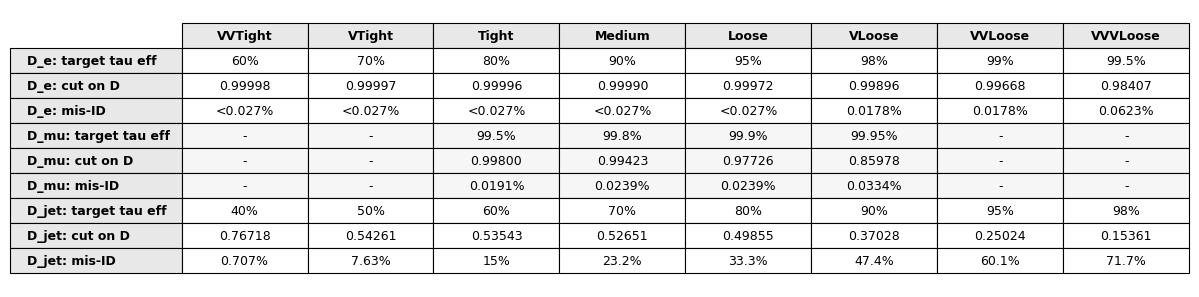

In [18]:
def print_grid(table):
    first = [f"{a if q=='target tau eff' else ''}" for a, q in table.index]
    second = [q for a, q in table.index]
    w0 = max(len(s) for s in first + ["D"])
    w1 = max(len(s) for s in second + [""])
    ws = [max(len(c), *(len(str(v)) for v in table[c])) for c in table.columns]
    def line(ch="-", joint="+"):
        return joint + joint.join(ch*(w+2) for w in [w0, w1] + ws) + joint
    def row(cells):
        return "|" + "|".join(" " + str(c).center(w) + " " for c, w in zip(cells, [w0, w1] + ws)) + "|"
    out = [line("="), row(["", ""] + list(table.columns)), line("=")]
    for i, ((a, q), vals) in enumerate(zip(table.index, table.values)):
        out.append(row([{"electron":"D_e","muon":"D_mu","jet":"D_jet"}[a] if q=="target tau eff" else "", q] + list(vals)))
        out.append(line("=") if q == "mis-ID" else line("-"))
    print("\n".join(out))

print_grid(table)

# ---- same table as a picture for slides/report ----
import matplotlib.pyplot as plt
disp = table.copy()
disp.index = [f"{ {'electron':'D_e','muon':'D_mu','jet':'D_jet'}[a] }: {q}" for a, q in table.index]
fig, ax = plt.subplots(figsize=(13, 3.6)); ax.axis("off")
tb = ax.table(cellText=disp.values, rowLabels=disp.index, colLabels=disp.columns, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.5)
for (r, c), cell in tb.get_celld().items():
    cell.set_linewidth(0.8)
    if r == 0 or c == -1: cell.set_text_props(weight="bold"); cell.set_facecolor("#e8e8e8")
    elif (r - 1) // 3 % 2 == 1: cell.set_facecolor("#f6f6f6")
plt.savefig("/kaggle/working/wp_table.png", dpi=200, bbox_inches="tight")
plt.show()